# Notebook 01: Initial Dataset Inspection & Data Quality Audit

> **Project**: Water Quality Prediction via Gradient Boosting & Deep Neural Networks  
> **Course**: Semester 5 Applied Machine Learning & Deep Learning (AML / DL)  
> **Deliverable**: Initial Dataset Inspection, Quality Audit & Diagnostic Visualizations  
> **Target Dataset**: Faculty-Provided Surface Water Quality Combined Dataset  
> **Output Report**: `reports/dataset_audit_report.md` | **Figures**: `reports/figures/`  

---

## Executive Summary & Objectives

The goal of this notebook is to execute a rigorous, reproducible initial inspection and data quality audit on the faculty-provided **Combined Data** dataset. High-capacity machine learning algorithms (such as XGBoost, Random Forest, and Deep Multi-Layer Perceptrons) are sensitive to data anomalies, telemetry sentinels, silent corruptions, and distribution skews. 

In this audit, we:
1. **Inspect and Identify**: Dynamically locate and identify the dataset without hardcoded path assumptions or schema preconceptions.
2. **Efficient Loading**: Ingest the multi-gigabyte/multi-million row dataset in pandas efficiently, demonstrating memory profiling and chunking techniques.
3. **Comprehensive Profiling**: Audit dimensions, schema, column data types, missing value percentages, duplicate rows, unique cardinality, and detailed numerical percentiles.
4. **Diagnostic Anomaly Auditing**: Detect hardware sentinels (e.g. `-999999.0`), impossible physical bounds (e.g. `pH = 67115.0`), detection limit zero offsets, and statistical outliers (Tukey IQR rule) **without deleting or altering any raw records**.
5. **Diagnostic Visualizations**: Render high-resolution figures for missingness patterns, sensor dropouts co-occurrence, numerical distributions, outlier boxplots, and continuous/categorical target distributions.
6. **Reproducible Artifacts**: Generate and export a standardized markdown audit report and publication-ready figures for downstream modeling handoff.


In [1]:
# Standard library imports
import os
import sys
import time
import psutil
import warnings
from typing import Dict, List, Optional, Tuple, Any

# Data manipulation and numerical operations
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress minor warnings for clean notebook presentation
warnings.filterwarnings('ignore', category=FutureWarning)

# Ensure project root is in sys.path dynamically whether running from project root or inside notebooks/
current_dir = os.path.abspath(os.getcwd())
if os.path.basename(current_dir) == 'notebooks':
    project_root = os.path.abspath(os.path.join(current_dir, '..'))
elif os.path.exists(os.path.join(current_dir, 'src', 'data_audit.py')):
    project_root = current_dir
else:
    project_root = os.path.abspath(os.path.join(current_dir, '..'))

if project_root not in sys.path:
    sys.path.insert(0, project_root)

# Import reusable audit functions from src/data_audit.py
from src.data_audit import (
    find_dataset_path,
    load_dataset,
    inspect_dataset_overview,
    audit_missingness,
    audit_duplicates,
    audit_unique_values,
    audit_numerical_statistics,
    audit_categorical_statistics,
    audit_suspicious_values_and_outliers,
    audit_target_distribution,
    generate_audit_visualizations,
    generate_audit_report,
)

# Plot styling configuration
sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)

print("Environment initialized successfully.")
print(f"Pandas version: {pd.__version__} | NumPy version: {np.__version__}")


Environment initialized successfully.
Pandas version: 3.0.6 | NumPy version: 2.5.4


## Task 1: Inspect Files & Dynamically Identify the Relevant Dataset

Rather than assuming hardcoded filenames or column schemas, we utilize `find_dataset_path()` from `src/data_audit.py`. This function scans the project directory hierarchy for dataset candidates (`.csv`, `.parquet`), computes file size metrics, scores candidate relevance using keyword heuristics (`combined`, `dataset`, `water`), and selects the primary master dataset.


In [2]:
# Search for dataset candidates relative to the project structure
search_paths = [
    os.path.join(project_root, 'data'),
    os.path.join(project_root, 'data', 'Dataset'),
    os.path.join(project_root, 'data', 'Dataset', 'Parquet', 'Combined Data'),
]

selected_file, discovered_candidates = find_dataset_path(search_dirs=search_paths)

# Display discovered candidate files
candidates_df = pd.DataFrame(discovered_candidates)
print(f"Total dataset candidates discovered: {len(candidates_df)}")
display(candidates_df[['file_name', 'format', 'size_mb', 'relative_path']].head(10))

print(f"\n--> Primary Selected Dataset: {selected_file}")


2026-10-21 14:53:29,450 [INFO] Discovered 17 data file candidates.


2026-10-21 14:53:29,451 [INFO]   [1] ../data/Dataset/Parquet/Combined Data/Combined_dataset.csv (CSV, 397.28 MB)


2026-10-21 14:53:29,451 [INFO]   [2] ../data/Dataset/Parquet/Combined Data/Combined_dataset.parquet (PARQUET, 60.52 MB)


2026-10-21 14:53:29,451 [INFO]   [3] ../data/GeneratedOutput/01.EDA/final_eda_cleaned_dataset.parquet (PARQUET, 60.39 MB)


2026-10-21 14:53:29,451 [INFO]   [4] ../data/Dataset/Parquet/Country-Wise Data/England_dataset.parquet (PARQUET, 46.76 MB)


2026-10-21 14:53:29,451 [INFO]   [5] ../data/Dataset/Parquet/Country-Wise Data/USA_dataset.parquet (PARQUET, 9.43 MB)


2026-10-21 14:53:29,451 [INFO] Selected primary dataset: ../data/Dataset/Parquet/Combined Data/Combined_dataset.csv


Total dataset candidates discovered: 17


,file_name,format,size_mb,relative_path
0,Combined_dataset.csv,CSV,397.28,../data/Dataset/Parquet/Combined Data/Combined...
1,Combined_dataset.parquet,PARQUET,60.52,../data/Dataset/Parquet/Combined Data/Combined...
2,final_eda_cleaned_dataset.parquet,PARQUET,60.39,../data/GeneratedOutput/01.EDA/final_eda_clean...
3,England_dataset.parquet,PARQUET,46.76,../data/Dataset/Parquet/Country-Wise Data/Engl...
4,USA_dataset.parquet,PARQUET,9.43,../data/Dataset/Parquet/Country-Wise Data/USA_...
5,Ireland_dataset.parquet,PARQUET,3.06,../data/Dataset/Parquet/Country-Wise Data/Irel...
6,China_dataset.parquet,PARQUET,0.41,../data/Dataset/Parquet/Country-Wise Data/Chin...
7,Canada_dataset.parquet,PARQUET,0.17,../data/Dataset/Parquet/Country-Wise Data/Cana...
8,India_dataset.parquet,PARQUET,0.11,../data/Dataset/Parquet/Country-Wise Data/Indi...
9,Australia_dataset.parquet,PARQUET,0.01,../data/Dataset/Parquet/Country-Wise Data/Aust...



--> Primary Selected Dataset: ../data/Dataset/Parquet/Combined Data/Combined_dataset.csv


## Task 2: Load the Data Efficiently Using Pandas

Handling large datasets (hundreds of megabytes to gigabytes, millions of rows) requires conscious memory management:
1. **Low Memory Mode**: We set `low_memory=False` to prevent pandas from guessing conflicting data types across arbitrary file chunks.
2. **Chunking Capability**: For machines with restricted RAM, `load_dataset()` supports `chunksize=...` to iterate over batches in a streaming fashion.
3. **Memory & I/O Profiling**: We record execution time and measure process RSS memory growth using `psutil`.


In [3]:
# Resolve dataset path relative to execution directory
if not os.path.exists(selected_file):
    resolved_path = os.path.join(project_root, selected_file)
else:
    resolved_path = selected_file

# Track system memory before loading
process = psutil.Process(os.getpid())
mem_before = process.memory_info().rss / (1024 * 1024)
t_start = time.time()

# Efficient pandas ingestion
df = load_dataset(resolved_path, low_memory=False)

t_elapsed = time.time() - t_start
mem_after = process.memory_info().rss / (1024 * 1024)
df_mem_mb = df.memory_usage(deep=True).sum() / (1024 * 1024)

print(f"Dataset successfully loaded in {t_elapsed:.2f} seconds.")
print(f"RAM utilized: +{mem_after - mem_before:.1f} MB (DataFrame deep size: {df_mem_mb:.1f} MB)")
print(f"Dimensions: {df.shape[0]:,} observations × {df.shape[1]} columns")


2026-10-21 14:53:29,471 [INFO] Loading data from: ../data/Dataset/Parquet/Combined Data/Combined_dataset.csv (extension: .csv)


2026-10-21 14:53:32,268 [INFO] Loaded CSV: 4,297,895 rows × 14 cols in 2.79s (~660.9 MB RAM)


Dataset successfully loaded in 2.80 seconds.
RAM utilized: +922.7 MB (DataFrame deep size: 660.9 MB)
Dimensions: 4,297,895 observations × 14 columns


## Task 3: Comprehensive Structural & Statistical Profiling

In this task, we audit:
- The exact number of rows and columns.
- Column names, inferred pandas dtypes, and non-null counts.
- Missing-value counts and percentages per feature.
- Duplicate rows and uniqueness cardinality.
- Full numerical summary statistics (including 1st, 5th, 25th, 50th, 75th, 95th, and 99th percentiles).
- Categorical modality breakdowns.


In [4]:
# 3.1 Structural Overview
overview = inspect_dataset_overview(df)

print(f"Rows: {overview['num_rows']:,}")
print(f"Columns: {overview['num_cols']}")
print(f"In-Memory Footprint: {overview['memory_mb']:.1f} MB")
print(f"Numerical Features ({len(overview['numerical_columns'])}): {overview['numerical_columns']}")
print(f"Categorical/Metadata Features ({len(overview['categorical_columns'])}): {overview['categorical_columns']}\n")

display(overview['summary_table'])


Rows: 4,297,895
Columns: 14
In-Memory Footprint: 660.9 MB
Numerical Features (9): ['Ammonia (mg/l)', 'Biochemical Oxygen Demand (mg/l)', 'Dissolved Oxygen (mg/l)', 'Orthophosphate (mg/l)', 'pH (ph units)', 'Temperature (cel)', 'Nitrogen (mg/l)', 'Nitrate (mg/l)', 'CCME_Values']
Categorical/Metadata Features (5): ['Country', 'Area', 'Waterbody Type', 'Date', 'CCME_WQI']



,index,column_name,dtype,non_null_count,missing_count,missing_percent,unique_count,unique_percent,sample_value
0,0,Country,str,4297895,0,0.000,7,0.0002,Australia
1,1,Area,str,4297895,0,0.000,64665,1.5046,Torrens River Adelaide Zoo Pedestrian Bridge
2,2,Waterbody Type,str,4297895,0,0.000,13,0.0003,River
3,3,Date,str,4297895,0,0.000,24013,0.5587,01-12-2014
4,4,Ammonia (mg/l),float64,2828064,1469831,34.199,13987,0.3254,0.083
5,5,Biochemical Oxygen Demand (mg/l),float64,2831561,1466334,34.117,4846,0.1128,1.3
6,6,Dissolved Oxygen (mg/l),float64,3156915,1140980,26.547,17731,0.4126,4.15
7,7,Orthophosphate (mg/l),float64,2828064,1469831,34.199,10596,0.2465,0.062
8,8,pH (ph units),float64,3096820,1201075,27.946,5218,0.1214,7.4
9,9,Temperature (cel),float64,4291337,6558,0.153,17265,0.4017,24.7


In [5]:
# 3.2 Missingness Profiling
missing_df, missing_summary = audit_missingness(df)

print("=" * 60)
print("MISSINGNESS AUDIT SUMMARY")
print("=" * 60)
print(f"Total Cells: {missing_summary['total_cells']:,}")
print(f"Missing Cells: {missing_summary['total_missing_cells']:,} ({missing_summary['overall_missing_percent']}%)")
print(f"Complete Rows (0 missing): {missing_summary['complete_rows_count']:,} ({missing_summary['complete_rows_percent']}%)")
print(f"Completely Clean Columns: {len(missing_summary['completely_clean_columns'])}")
print(f"Columns with Missingness: {len(missing_summary['columns_with_missing'])}\n")

display(missing_df)


MISSINGNESS AUDIT SUMMARY
Total Cells: 60,170,530
Missing Cells: 9,690,871 (16.106%)
Complete Rows (0 missing): 2,827,977 (65.799%)
Completely Clean Columns: 6
Columns with Missingness: 8



,column,missing_count,missing_percentage,severity
0,Ammonia (mg/l),1469831,34.199,Moderate (1-35%)
1,Orthophosphate (mg/l),1469831,34.199,Moderate (1-35%)
2,Nitrogen (mg/l),1469831,34.199,Moderate (1-35%)
3,Nitrate (mg/l),1466431,34.120,Moderate (1-35%)
4,Biochemical Oxygen Demand (mg/l),1466334,34.117,Moderate (1-35%)
5,pH (ph units),1201075,27.946,Moderate (1-35%)
6,Dissolved Oxygen (mg/l),1140980,26.547,Moderate (1-35%)
7,Temperature (cel),6558,0.153,Low (<1%)
8,Country,0,0.000,Complete (0%)
9,Area,0,0.000,Complete (0%)


In [6]:
# 3.3 Duplicates & Unique Values Cardinality
dup_summary = audit_duplicates(df)
print(f"Exact Duplicate Rows: {dup_summary['num_duplicates']:,} ({dup_summary['duplicate_percentage']}%)")
if dup_summary['num_duplicates'] > 0:
    print("Sample duplicate records:")
    display(dup_summary['sample_duplicates'].head(3))

# Unique value cardinality breakdown
unique_df = audit_unique_values(df)
print("\nCardinality Classification across features:")
display(unique_df)


Exact Duplicate Rows: 10,005 (0.2328%)
Sample duplicate records:


,Country,Area,Waterbody Type,Date,Ammonia (mg/l),Biochemical Oxygen Demand (mg/l),Dissolved Oxygen (mg/l),Orthophosphate (mg/l),pH (ph units),Temperature (cel),Nitrogen (mg/l),Nitrate (mg/l),CCME_Values,CCME_WQI
3603,Canada,SE616397-135001,River,10-04-2004,0.032844,2.13333,9.824,0.061,8.23,12.00,0.890,5.836820,93.116725,Good
3609,Canada,ESGV09089001,River,12-01-2009,0.043792,2.12500,9.824,0.003,7.08,26.66,0.088,2.001004,93.188249,Good
3611,Canada,HR21001,River,12-01-2012,0.139748,1.32750,11.400,0.004,7.02,20.05,0.488,3.375587,100.000000,Excellent



Cardinality Classification across features:


,column,unique_count,unique_ratio,cardinality,most_frequent_value,most_frequent_count,most_frequent_percent
0,Country,7,0.00000,Low Cardinality (Categorical),England,2129198,49.540
1,Area,64665,0.01505,Medium Cardinality,Lake Washington,54281,1.263
2,Waterbody Type,13,0.00000,Low Cardinality (Categorical),River,1856281,43.190
3,Date,24013,0.00559,Medium Cardinality,12-03-2018,1259,0.029
4,Ammonia (mg/l),13987,0.00325,Medium Cardinality,0.03,526717,12.255
5,Biochemical Oxygen Demand (mg/l),4846,0.00113,Medium Cardinality,2.7,686787,15.980
6,Dissolved Oxygen (mg/l),17731,0.00413,Medium Cardinality,10.2,895481,20.835
7,Orthophosphate (mg/l),10596,0.00247,Medium Cardinality,0.144,444309,10.338
8,pH (ph units),5218,0.00121,Medium Cardinality,7.78,367499,8.551
9,Temperature (cel),17265,0.00402,Medium Cardinality,11.46,311639,7.251


In [7]:
# 3.4 Numerical Summary Statistics & Extreme Percentiles
num_stats = audit_numerical_statistics(df)
print("Summary Statistics for Numerical Predictors & Targets:")
display(num_stats)


Summary Statistics for Numerical Predictors & Targets:


,column,count,mean,std,min,p01,p05,p25 (Q1),median (Q2),p75 (Q3),p95,p99,max,IQR,skewness,kurtosis
0,Ammonia (mg/l),2828064,1.1713,5.6688,-0.0050,0.0090,0.0210,0.0300,0.055,0.317,4.45,26.70,200.00,0.2870,12.0040,2.224228e+02
1,Biochemical Oxygen Demand (mg/l),2831561,4.8875,16.4226,-2.0000,0.6900,1.0000,1.6000,2.700,2.830,11.70,68.20,534.50,1.2300,10.2520,1.186596e+02
2,Dissolved Oxygen (mg/l),3156915,9.4699,562.8277,-999999.0000,2.0500,5.0000,9.3900,10.200,10.900,12.20,13.70,23.75,1.5100,-1776.7331,3.156825e+06
3,Orthophosphate (mg/l),2828064,0.7105,2.0894,-0.0040,0.0040,0.0100,0.0400,0.107,0.227,4.90,9.14,100.00,0.1870,8.9534,2.062282e+02
4,pH (ph units),3096820,6.8292,985.4009,-999999.0000,6.3300,6.9800,7.5100,7.780,8.000,8.33,8.73,67115.00,0.4900,-1012.3303,1.027464e+06
5,Temperature (cel),4291337,-4.8807,4317.6833,-999999.0000,1.7000,4.5500,9.3000,11.900,17.200,27.35,31.40,98.00,7.9000,-231.5995,5.363650e+04
6,Nitrogen (mg/l),2828064,5.2094,6.2004,0.0000,0.0190,0.2000,0.7800,4.000,6.320,18.30,30.30,46.00,5.5400,2.3939,7.228000e+00
7,Nitrate (mg/l),2831464,4.7636,6.0930,0.0000,0.0450,0.2000,1.1700,4.500,4.940,14.50,28.30,790.02,3.7700,6.9556,1.793175e+02
8,CCME_Values,4297895,89.6147,15.7517,31.3041,41.7981,48.0799,88.2691,100.000,100.000,100.00,100.00,100.00,11.7309,-1.7600,2.099700e+00


In [8]:
# 3.5 Categorical Modalities Breakdown
cat_stats = audit_categorical_statistics(df, top_n=5)
print("Categorical Modalities & Frequency Breakdown:")
display(cat_stats)


Categorical Modalities & Frequency Breakdown:


,column,count,missing,unique_categories,top_categories
0,Country,4297895,0,7,"England: 2,129,198 (49.54%); USA: 1,879,966 (4..."
1,Area,4297895,0,64665,"Lake Washington: 54,281 (1.26%); Hou Bay: 45,9..."
2,Waterbody Type,4297895,0,13,"River: 1,856,281 (43.19%); Stream: 1,466,152 (..."
3,Date,4297895,0,24013,"12-03-2018: 1,259 (0.03%); 12-11-2019: 1,146 (..."
4,CCME_WQI,4297895,0,5,"Excellent: 2,155,328 (50.15%); Good: 1,368,562..."


## Task 4: Identify Suspicious Values, Inconsistent Types & Potential Outliers

> **CRITICAL DATA ETHICS REQUIREMENT**:  
> Per project specifications, **no records are deleted or modified automatically** during the audit.  
> The raw data remains intact while anomalies, sentinels, and outliers are systematically flagged for informed downstream preprocessing.

We evaluate four categories of anomalies:
1. **Hardware / Telemetry Error Sentinels**: Values such as `-999999.0` recorded when sensors fail or lose power.
2. **Sensor Scaling Corruptions & Multiplier Errors**: Values such as `pH = 67115.0` resulting from missing decimal calibration.
3. **Detection Limit Baseline Offsets**: Small negative values (e.g. Ammonia `-0.005 mg/L`, BOD `-2.0 mg/L`) representing instrument zero-offset noise below detection thresholds.
4. **Statistical Outliers**: Points exceeding Tukey's IQR boundaries ($1.5 	imes 	ext{IQR}$ for mild outliers and $3.0 	imes 	ext{IQR}$ for extreme outliers).


In [9]:
# Run comprehensive suspicious value and outlier audit
outlier_df, outlier_summary = audit_suspicious_values_and_outliers(df)

print("=" * 70)
print("ANOMALY & OUTLIER AUDIT RESULTS")
print("=" * 70)
print(f"Features with Telemetry Sentinels: {outlier_summary['features_with_sentinels']}")
print(f"Features with Negative Concentrations: {outlier_summary['features_with_negatives']}")
print(f"Features with Domain Physical Violations: {outlier_summary['features_with_domain_violations']}\n")

display(outlier_df)

print("\nCategorical Type & Whitespace Inconsistencies:")
display(outlier_summary['type_inconsistencies_table'])


ANOMALY & OUTLIER AUDIT RESULTS
Features with Telemetry Sentinels: ['Dissolved Oxygen (mg/l)', 'pH (ph units)', 'Temperature (cel)']
Features with Negative Concentrations: ['Ammonia (mg/l)', 'Biochemical Oxygen Demand (mg/l)', 'Dissolved Oxygen (mg/l)', 'Orthophosphate (mg/l)', 'pH (ph units)', 'Temperature (cel)']
Features with Domain Physical Violations: ['Ammonia (mg/l)', 'Biochemical Oxygen Demand (mg/l)', 'Dissolved Oxygen (mg/l)', 'Orthophosphate (mg/l)', 'pH (ph units)', 'Temperature (cel)']



,column,total_non_null,negative_count,negative_pct,sentinels_detected,sentinel_values,domain_violations,domain_violation_notes,mild_outliers_iqr1.5,mild_outliers_pct,extreme_outliers_iqr3.0,extreme_outliers_pct,iqr_lower_mild,iqr_upper_mild
0,Ammonia (mg/l),2828064,2,0.0001,0,None,2,"2 outside [0.0, 500.0] (samples: [-0.005, -0.0...",404724,14.311,325018,11.493,-0.401,0.748
1,Biochemical Oxygen Demand (mg/l),2831561,2,0.0001,0,None,2,"2 outside [0.0, 1000.0] (samples: [-2.0, -0.02])",413563,14.605,295653,10.441,-0.245,4.675
2,Dissolved Oxygen (mg/l),3156915,95,0.0030,1,{-999999.0: 1},95,"95 outside [0.0, 30.0] (samples: [-0.05, -0.05...",373323,11.826,142526,4.515,7.125,13.165
3,Orthophosphate (mg/l),2828064,10,0.0004,0,None,10,"10 outside [0.0, 200.0] (samples: [-0.003, -0....",470130,16.624,392689,13.885,-0.240,0.507
4,pH (ph units),3096820,4,0.0001,4,"{-999999.0: 3, 67115.0: 1}",597,"597 outside [0.0, 14.0] (samples: [19.445, 19....",116233,3.753,23442,0.757,6.775,8.735
5,Temperature (cel),4291337,1877,0.0437,80,{-999999.0: 80},6067,"6,067 outside [-5.0, 50.0] (samples: [89.0, 92...",131805,3.071,7496,0.175,-2.550,29.050
6,Nitrogen (mg/l),2828064,0,0.0000,0,None,0,None,216434,7.653,81858,2.894,-7.530,14.630
7,Nitrate (mg/l),2831464,0,0.0000,0,None,0,None,251227,8.873,112907,3.988,-4.485,10.595
8,CCME_Values,4297895,0,0.0000,0,None,0,None,546719,12.721,299822,6.976,70.673,117.596



Categorical Type & Whitespace Inconsistencies:


,column,leading_trailing_whitespace_count,empty_string_count,unparsed_null_strings_count
0,Country,0,0,0
1,Area,6738,0,184
2,Waterbody Type,0,0,0
3,Date,0,0,0
4,CCME_WQI,0,0,0


## Task 5: Diagnostic Visualizations

We generate and display publication-grade diagnostic plots:
1. **Missingness Severity**: Horizontal bar chart identifying data completeness tiers.
2. **Missingness Co-occurrence Heatmap**: Proving that nutrient parameters drop in synchronized laboratory batches.
3. **Numerical Distributions**: Histograms with KDE curves (robustly trimmed to 1st-99th percentiles to reveal distribution geometry despite extreme sentinels).
4. **Outlier Boxplots**: Visualizing data spread and Tukey IQR limits.
5. **Target Variable Distributions**: Examining regression score density (`CCME_Values`) and categorical class balance (`CCME_WQI`).
6. **Spearman Correlation Matrix**: Rank correlations between physical-chemical features and water quality.


In [10]:
# Set destination for high-resolution figure artifacts
fig_dir = os.path.join(project_root, 'reports', 'figures')
saved_figs = generate_audit_visualizations(df, output_dir=fig_dir, sample_size=250000)

print(f"Generated and saved {len(saved_figs)} diagnostic figures to: {fig_dir}\n")
for name, path in saved_figs.items():
    print(f"  • {name}: {os.path.relpath(path, project_root)}")


2026-10-21 14:53:38,603 [INFO] Subsampling 250,000 rows from 4,297,895 for visualization rendering...


2026-10-21 14:53:38,905 [INFO] Saved: /Users/chaitanyakumar/Desktop/Semester_5_AML_DL/reports/figures/01_missingness_overview.png


2026-10-21 14:53:39,119 [INFO] Saved: /Users/chaitanyakumar/Desktop/Semester_5_AML_DL/reports/figures/02_missingness_correlation.png


2026-10-21 14:53:40,898 [INFO] Saved: /Users/chaitanyakumar/Desktop/Semester_5_AML_DL/reports/figures/03_numerical_distributions.png


2026-10-21 14:53:41,749 [INFO] Saved: /Users/chaitanyakumar/Desktop/Semester_5_AML_DL/reports/figures/04_outlier_boxplots.png


2026-10-21 14:53:44,668 [INFO] Saved: /Users/chaitanyakumar/Desktop/Semester_5_AML_DL/reports/figures/05_target_distributions.png


2026-10-21 14:53:45,589 [INFO] Saved: /Users/chaitanyakumar/Desktop/Semester_5_AML_DL/reports/figures/06_correlation_matrix.png


Generated and saved 6 diagnostic figures to: /Users/chaitanyakumar/Desktop/Semester_5_AML_DL/reports/figures

  • missingness_overview: reports/figures/01_missingness_overview.png
  • missingness_correlation: reports/figures/02_missingness_correlation.png
  • numerical_distributions: reports/figures/03_numerical_distributions.png
  • outlier_boxplots: reports/figures/04_outlier_boxplots.png
  • target_distributions: reports/figures/05_target_distributions.png
  • correlation_matrix: reports/figures/06_correlation_matrix.png


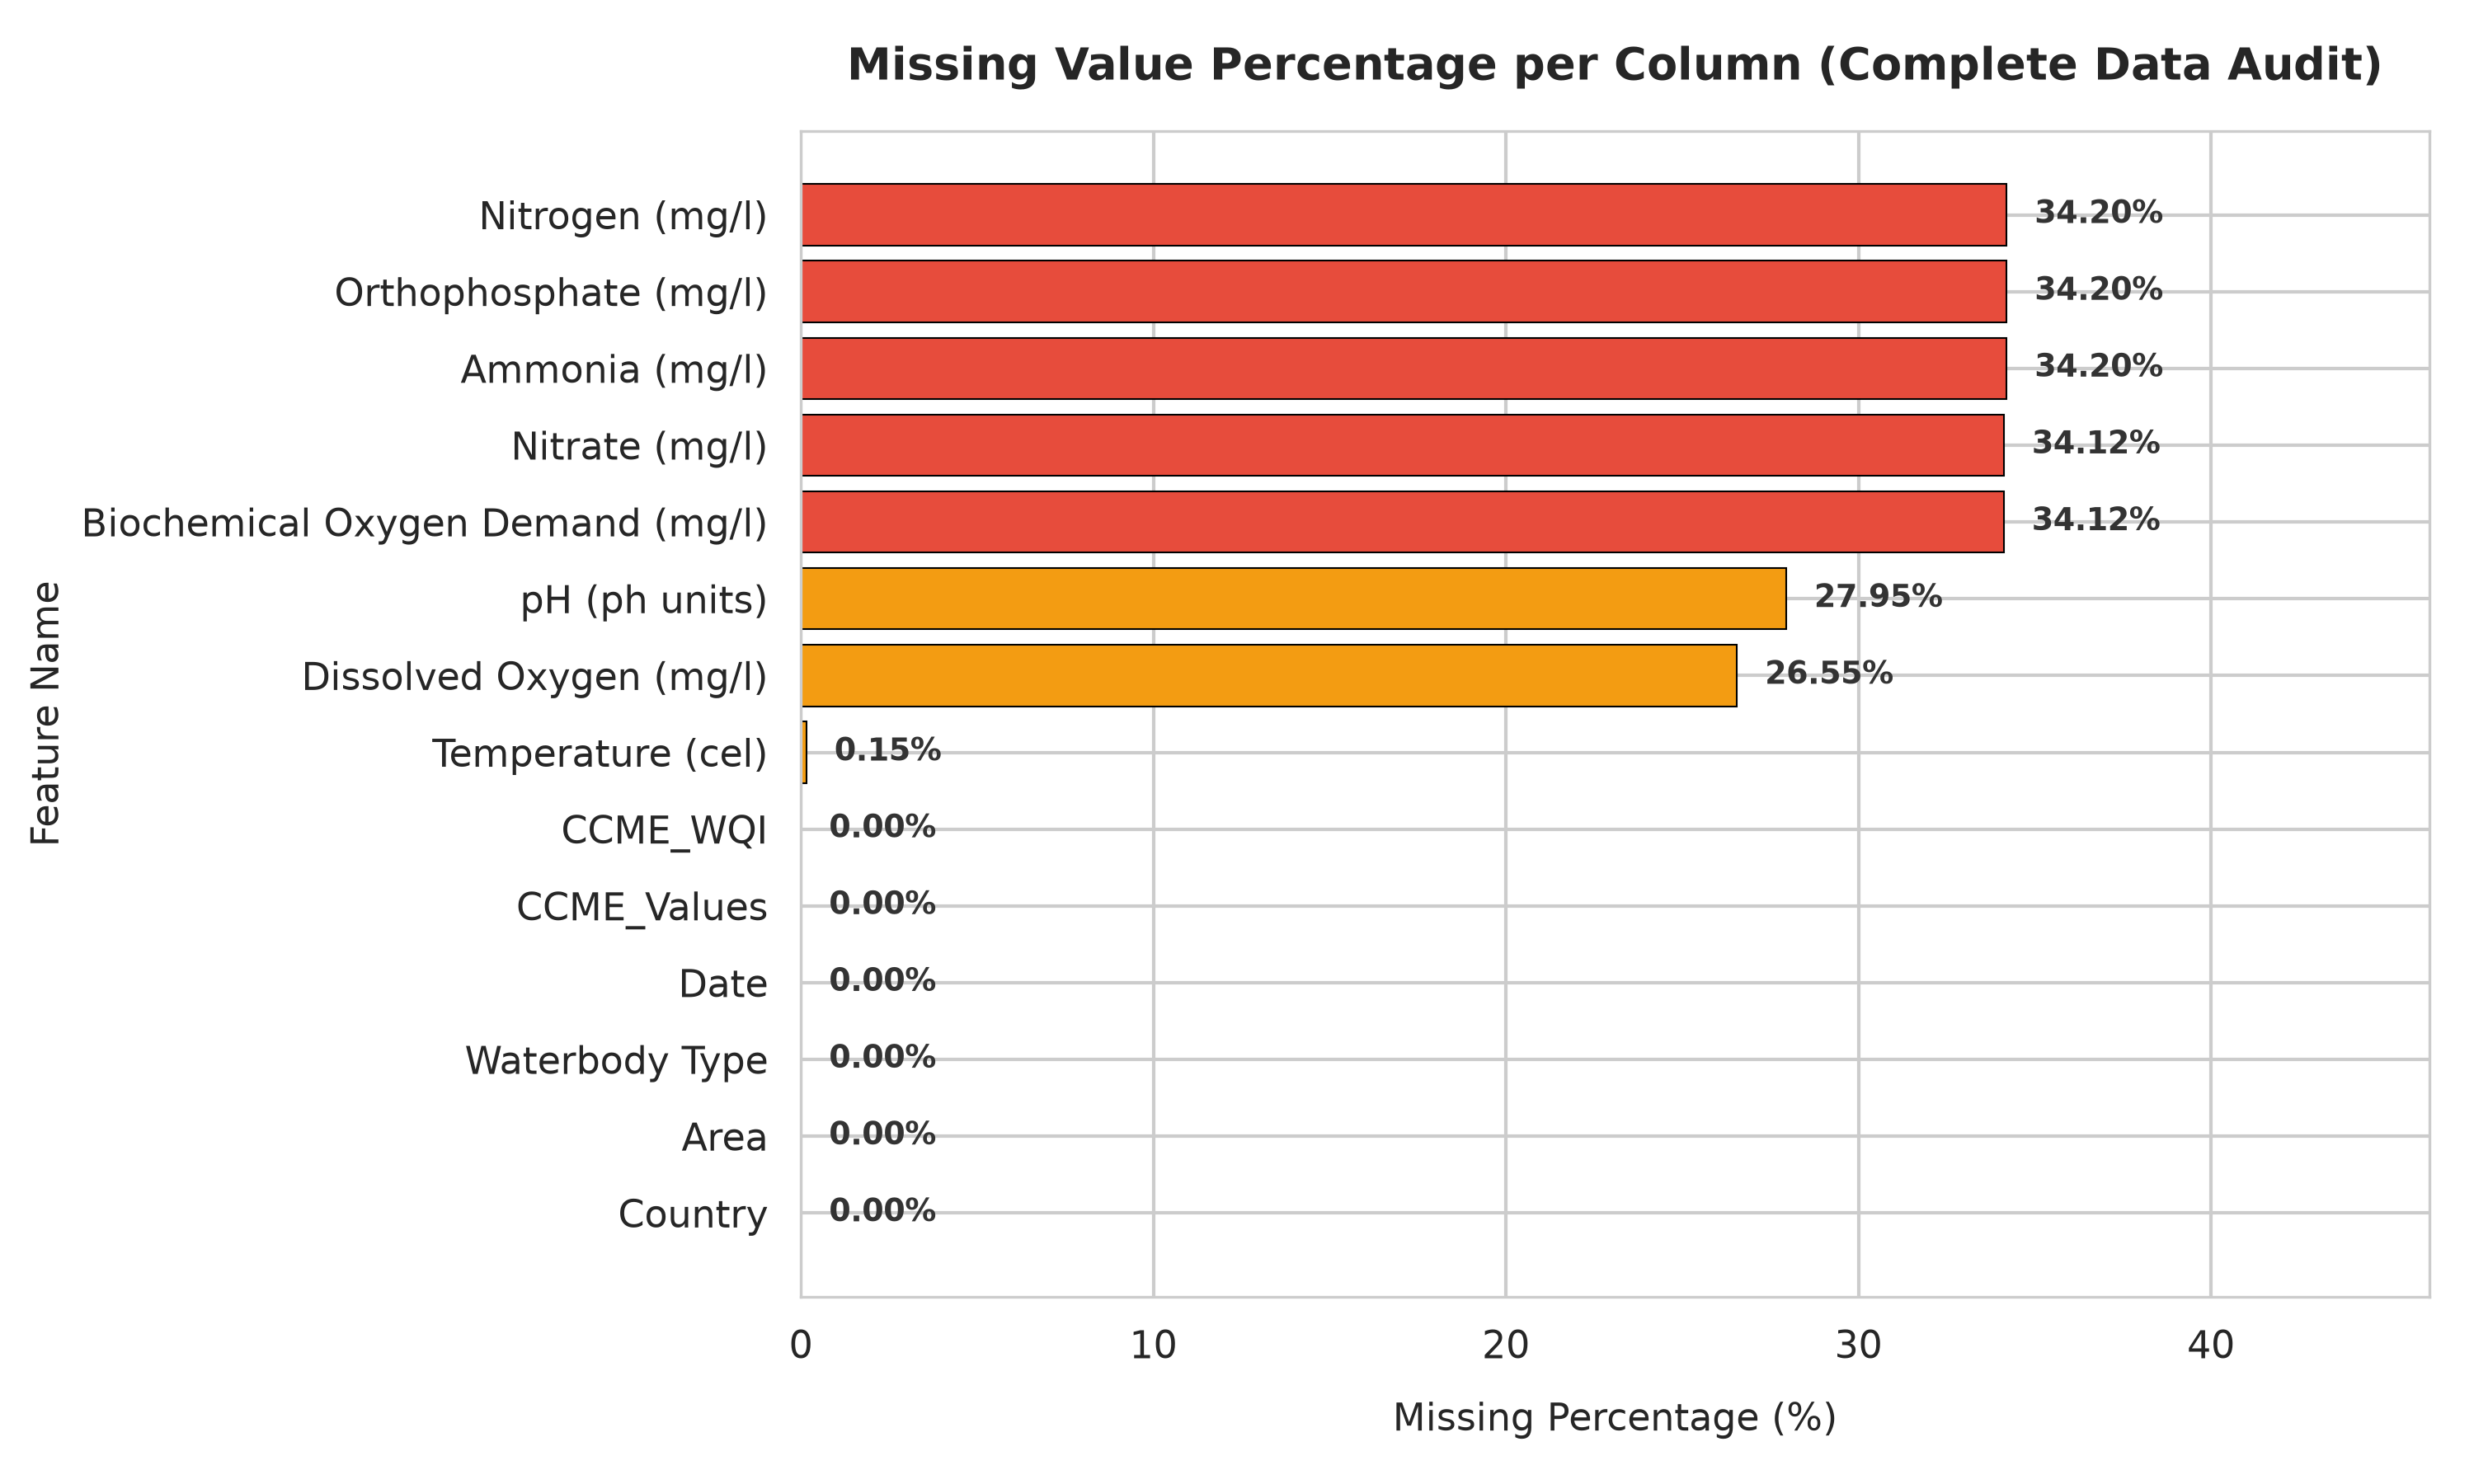

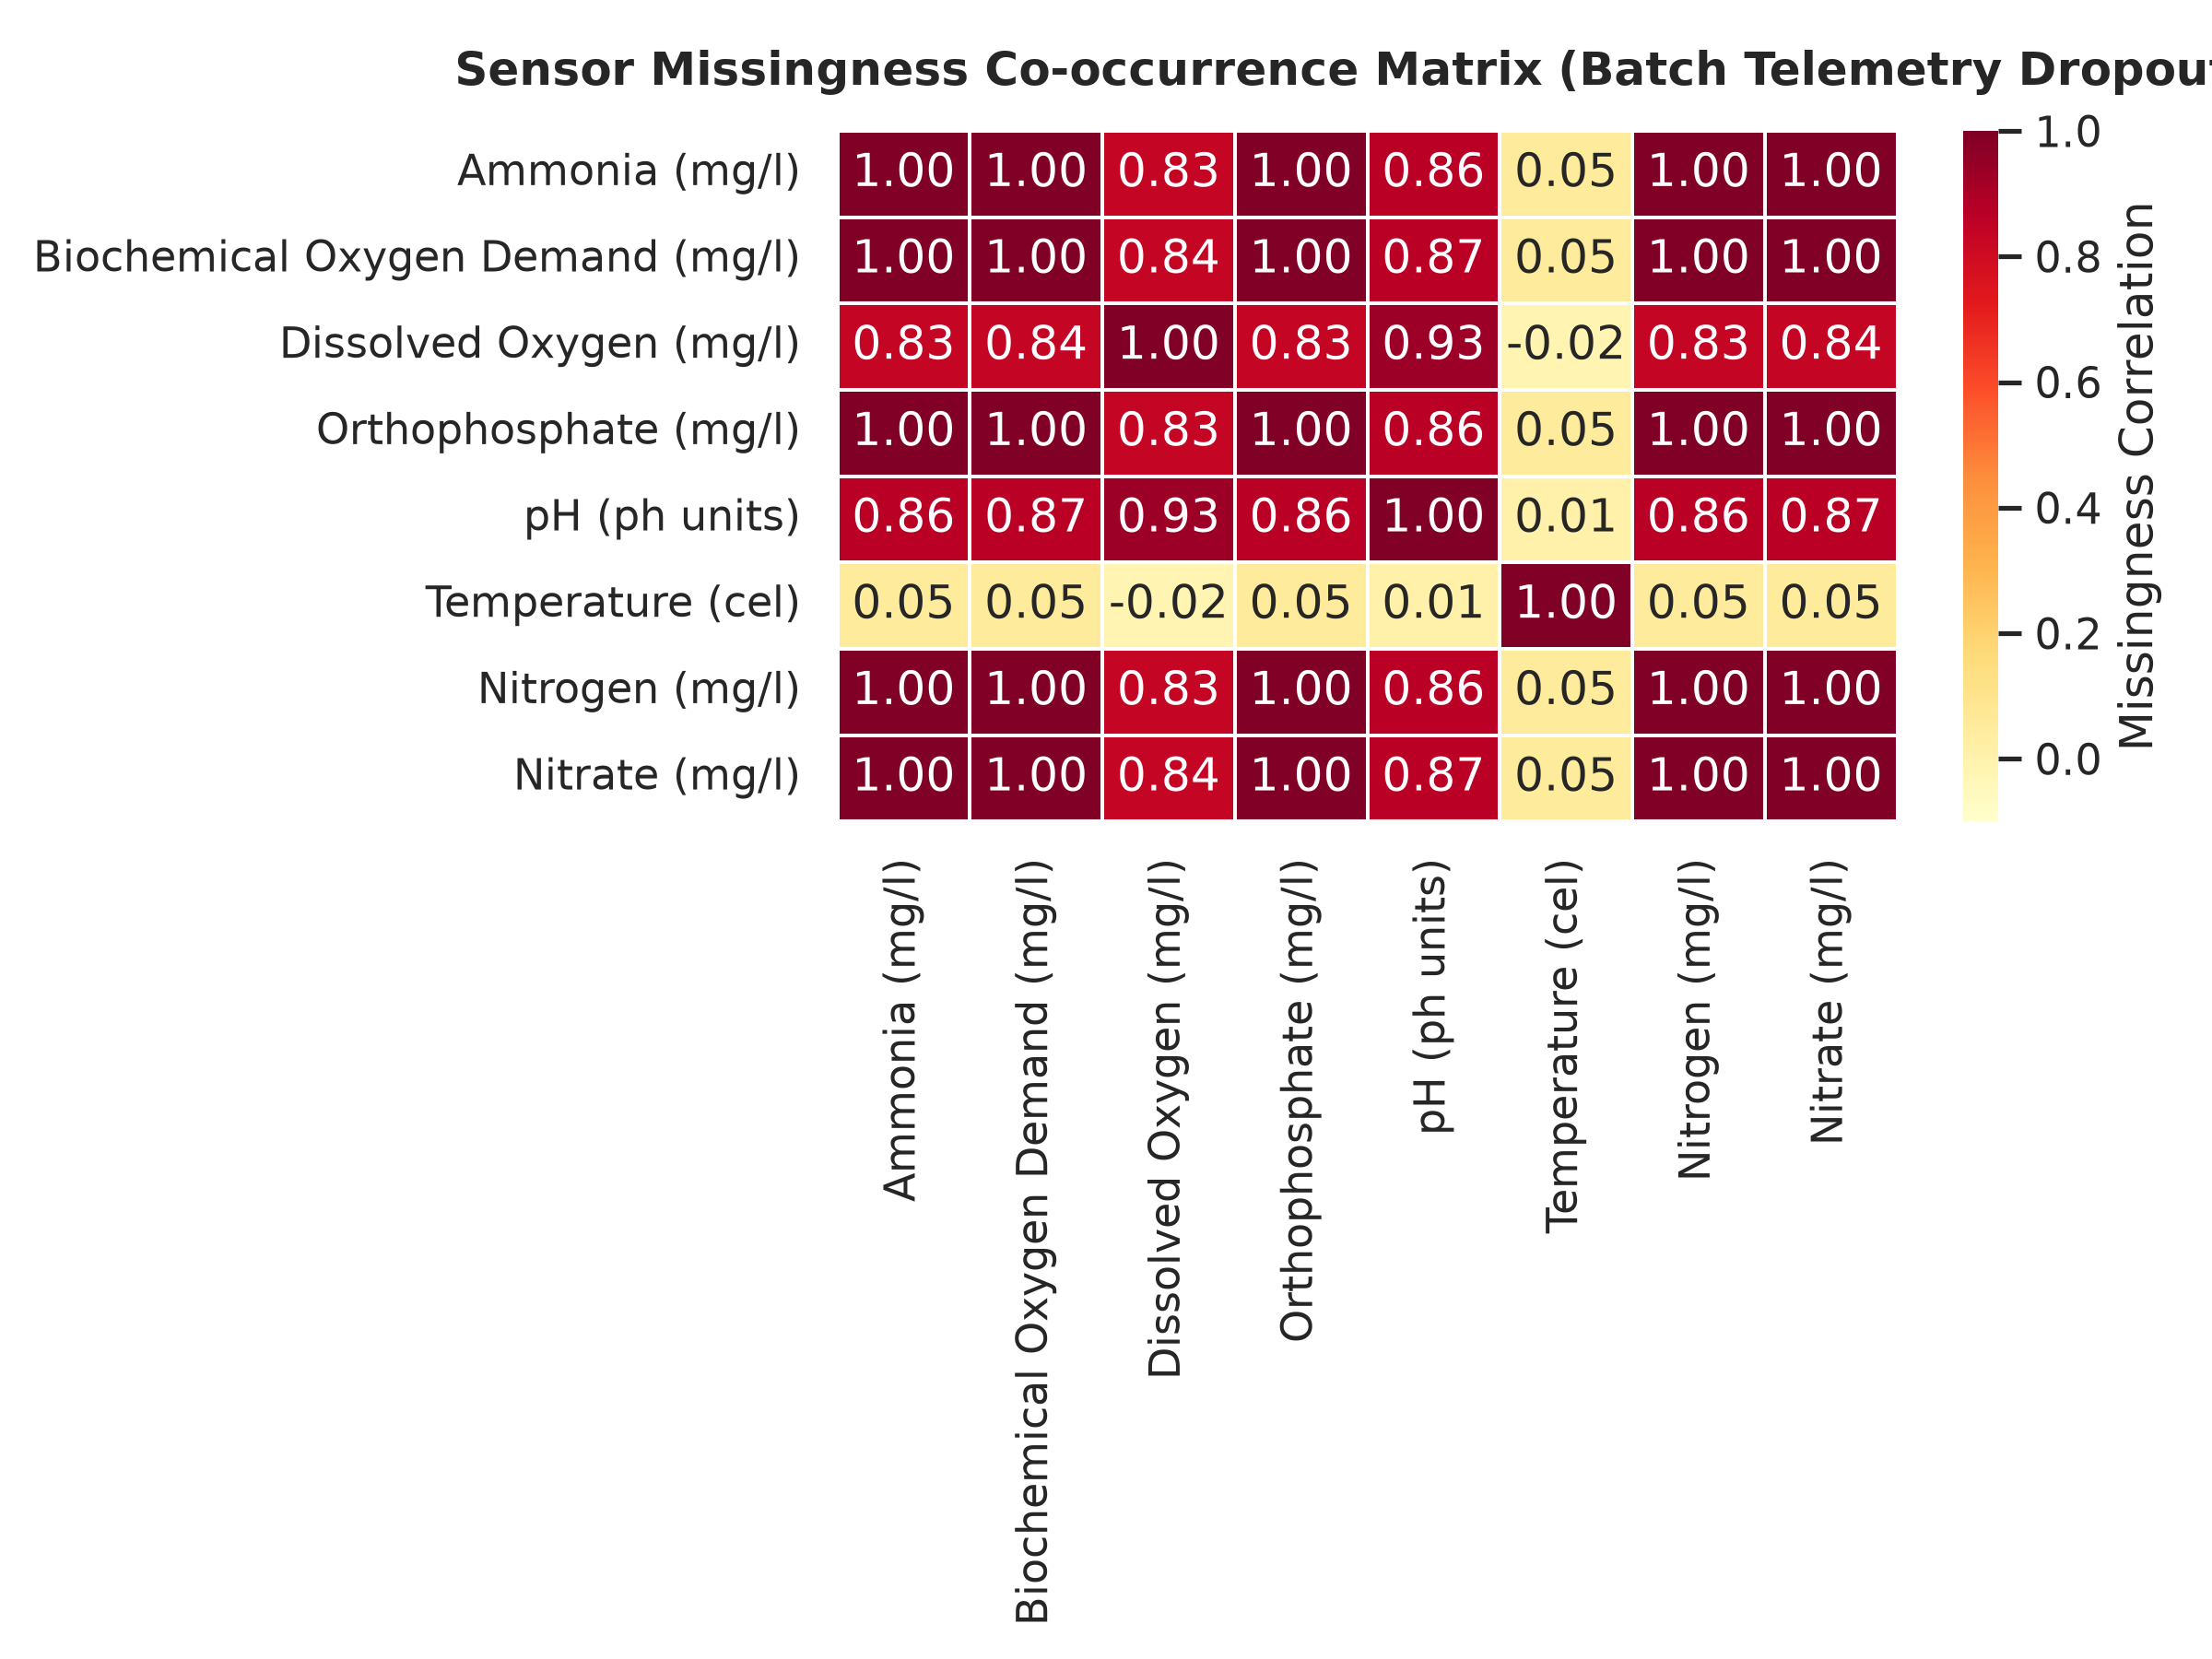

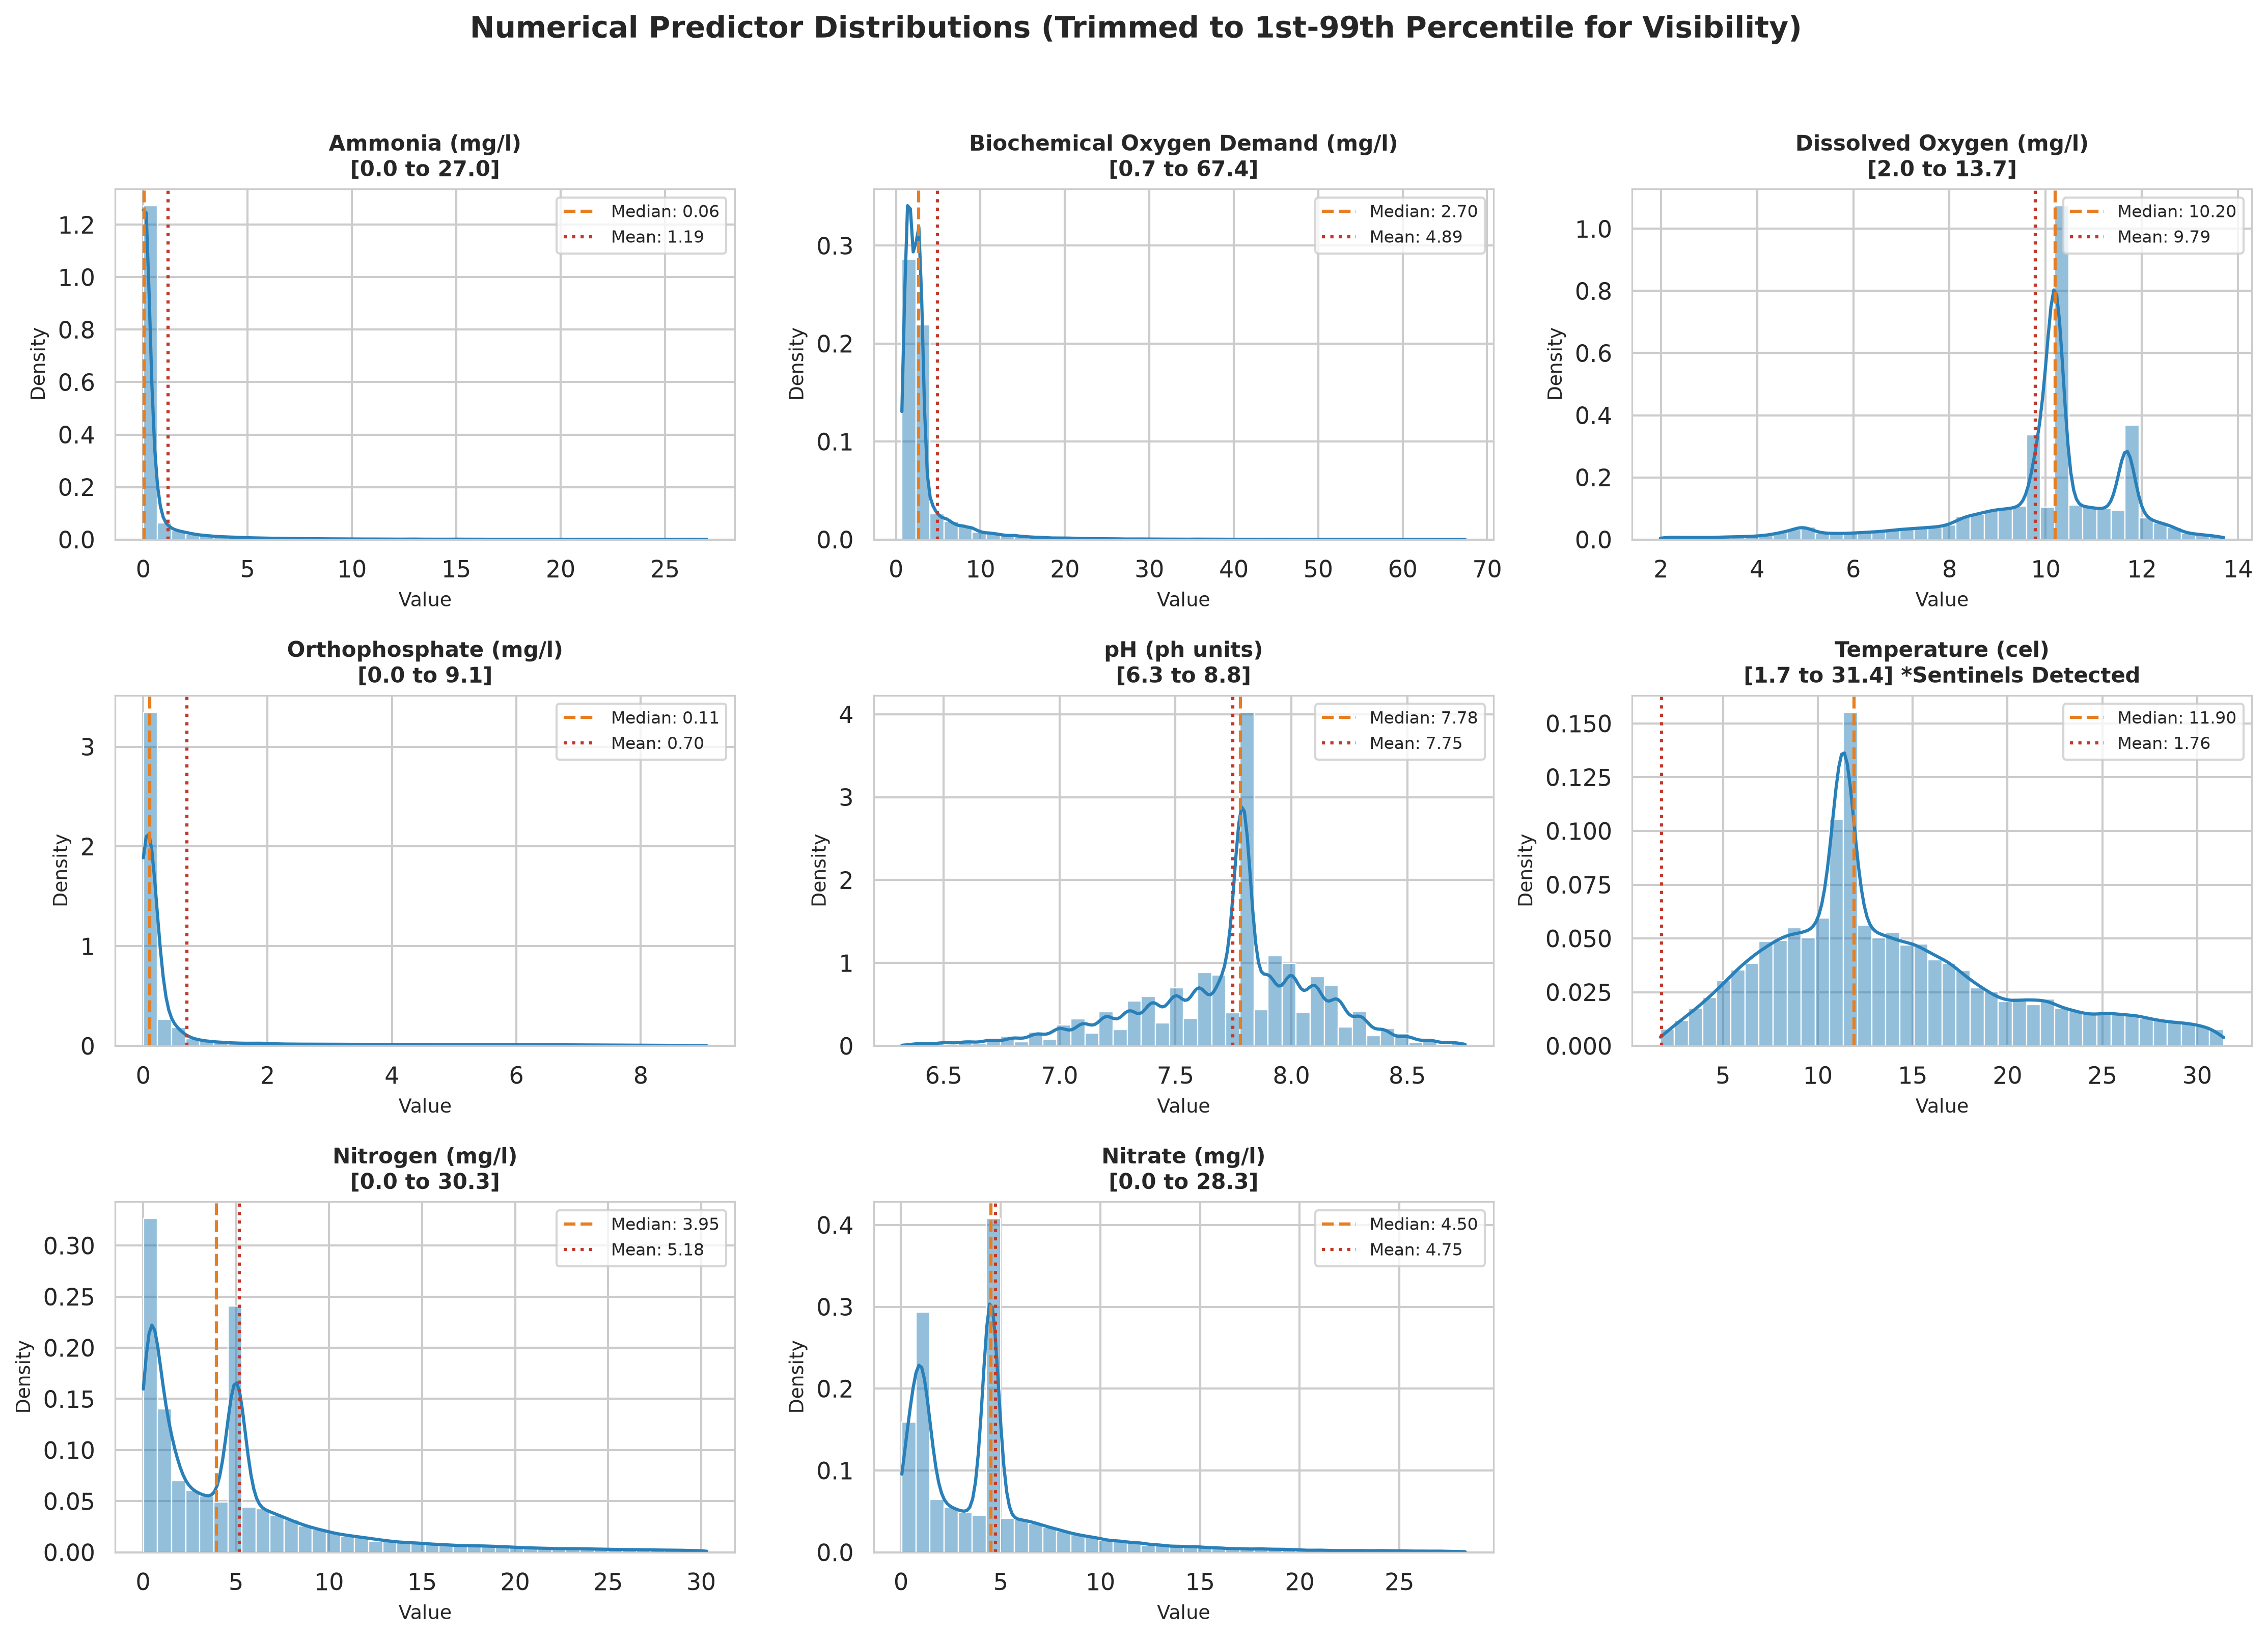

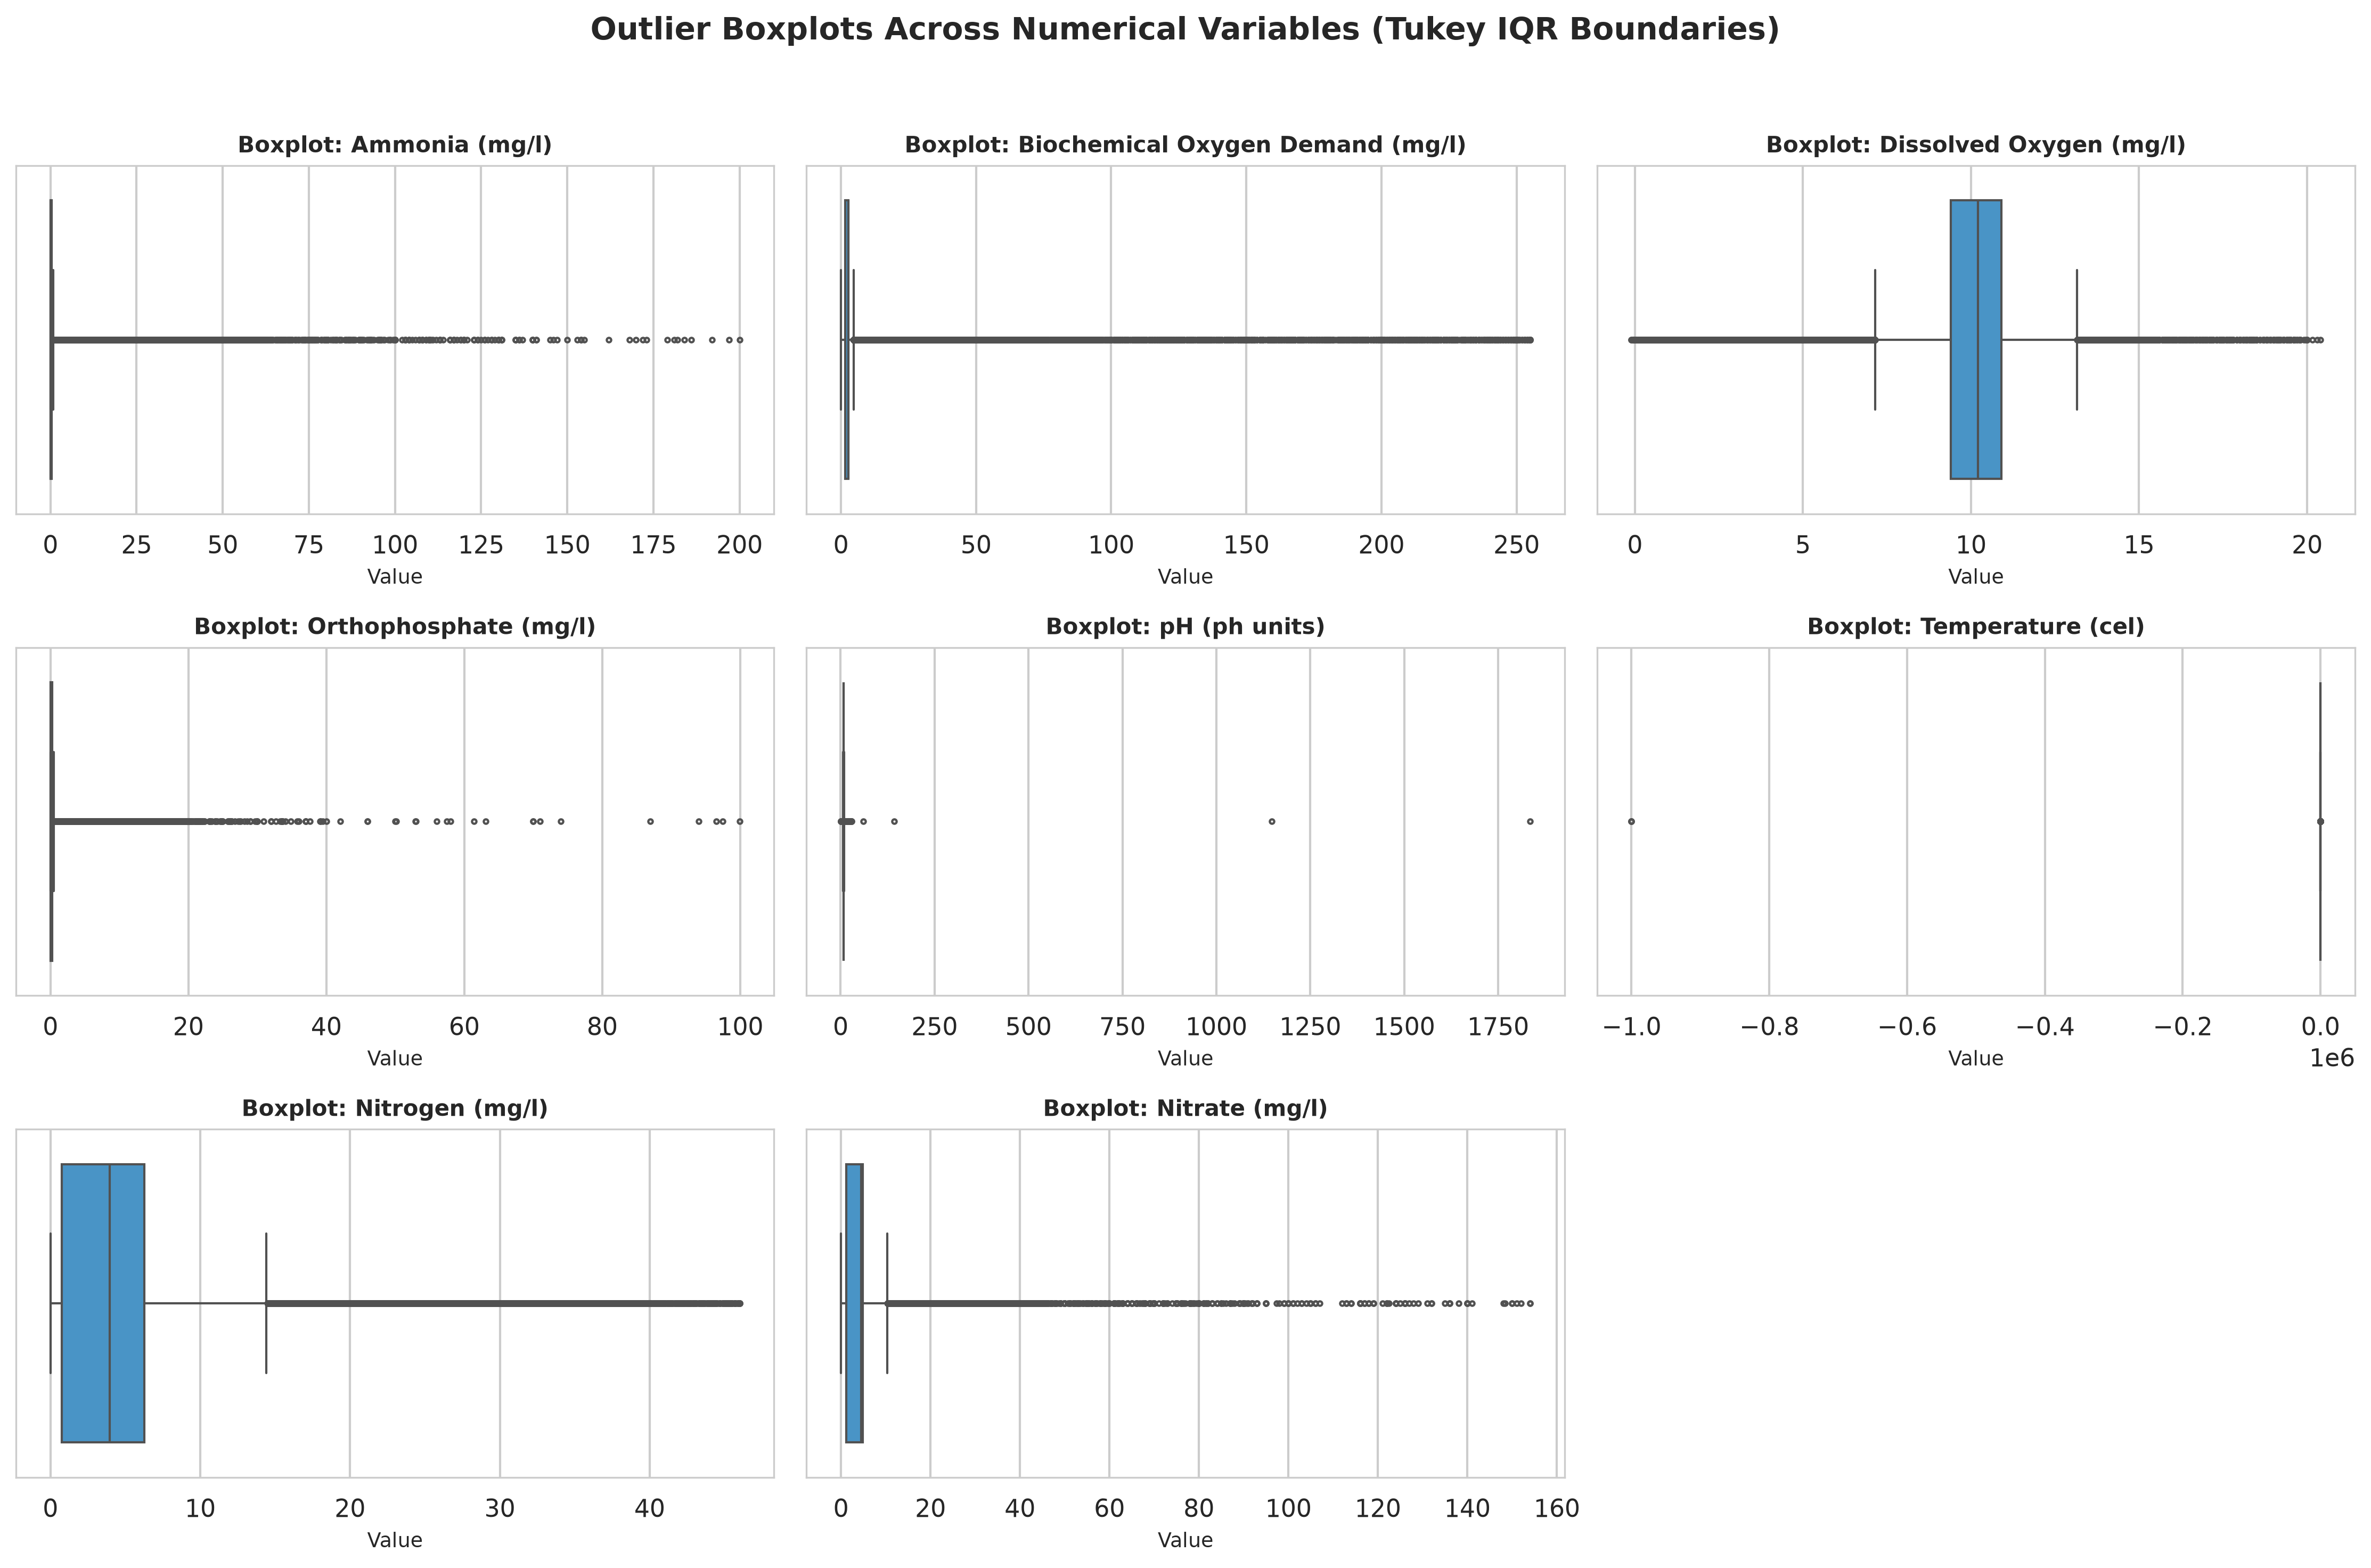

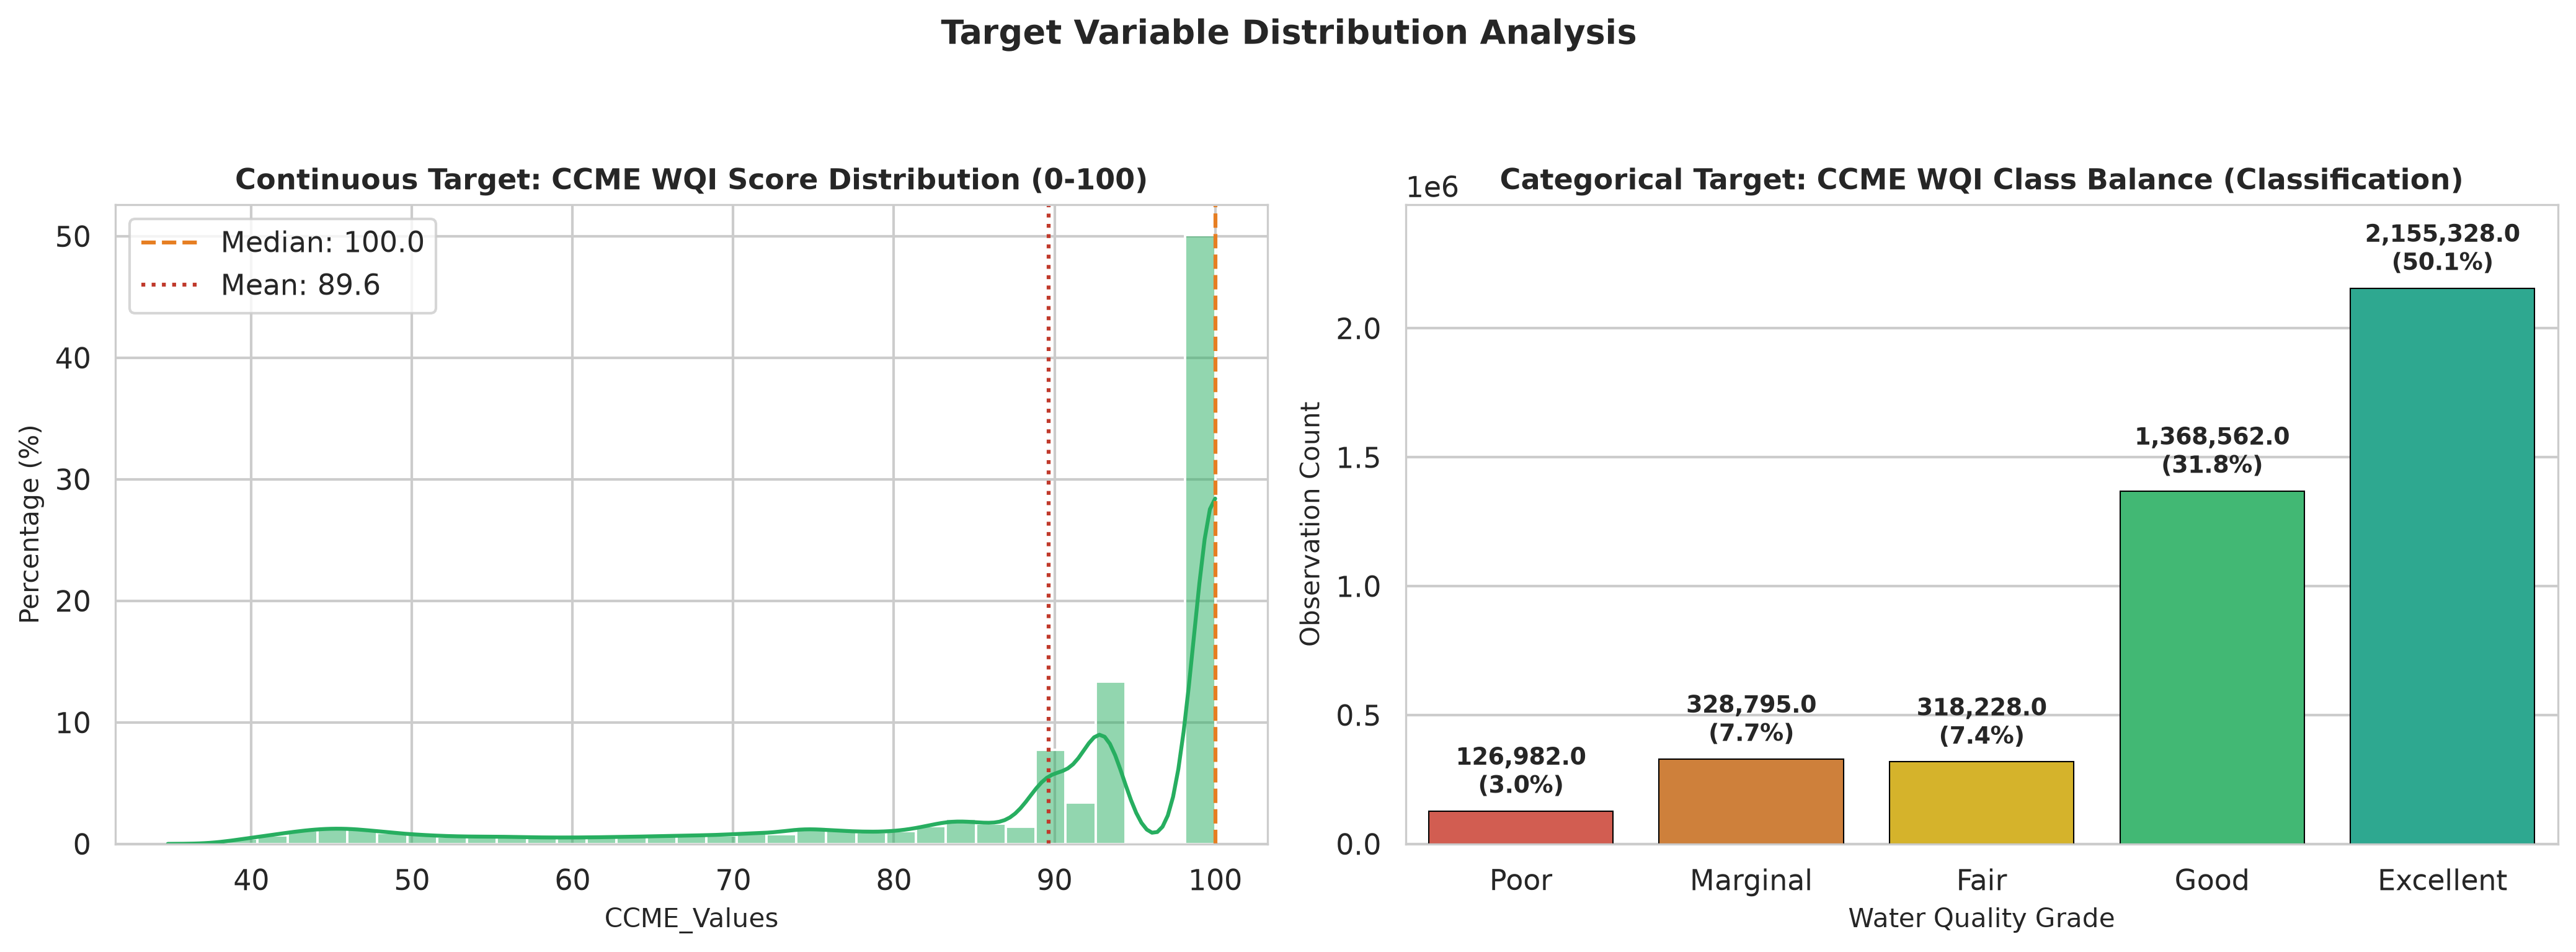

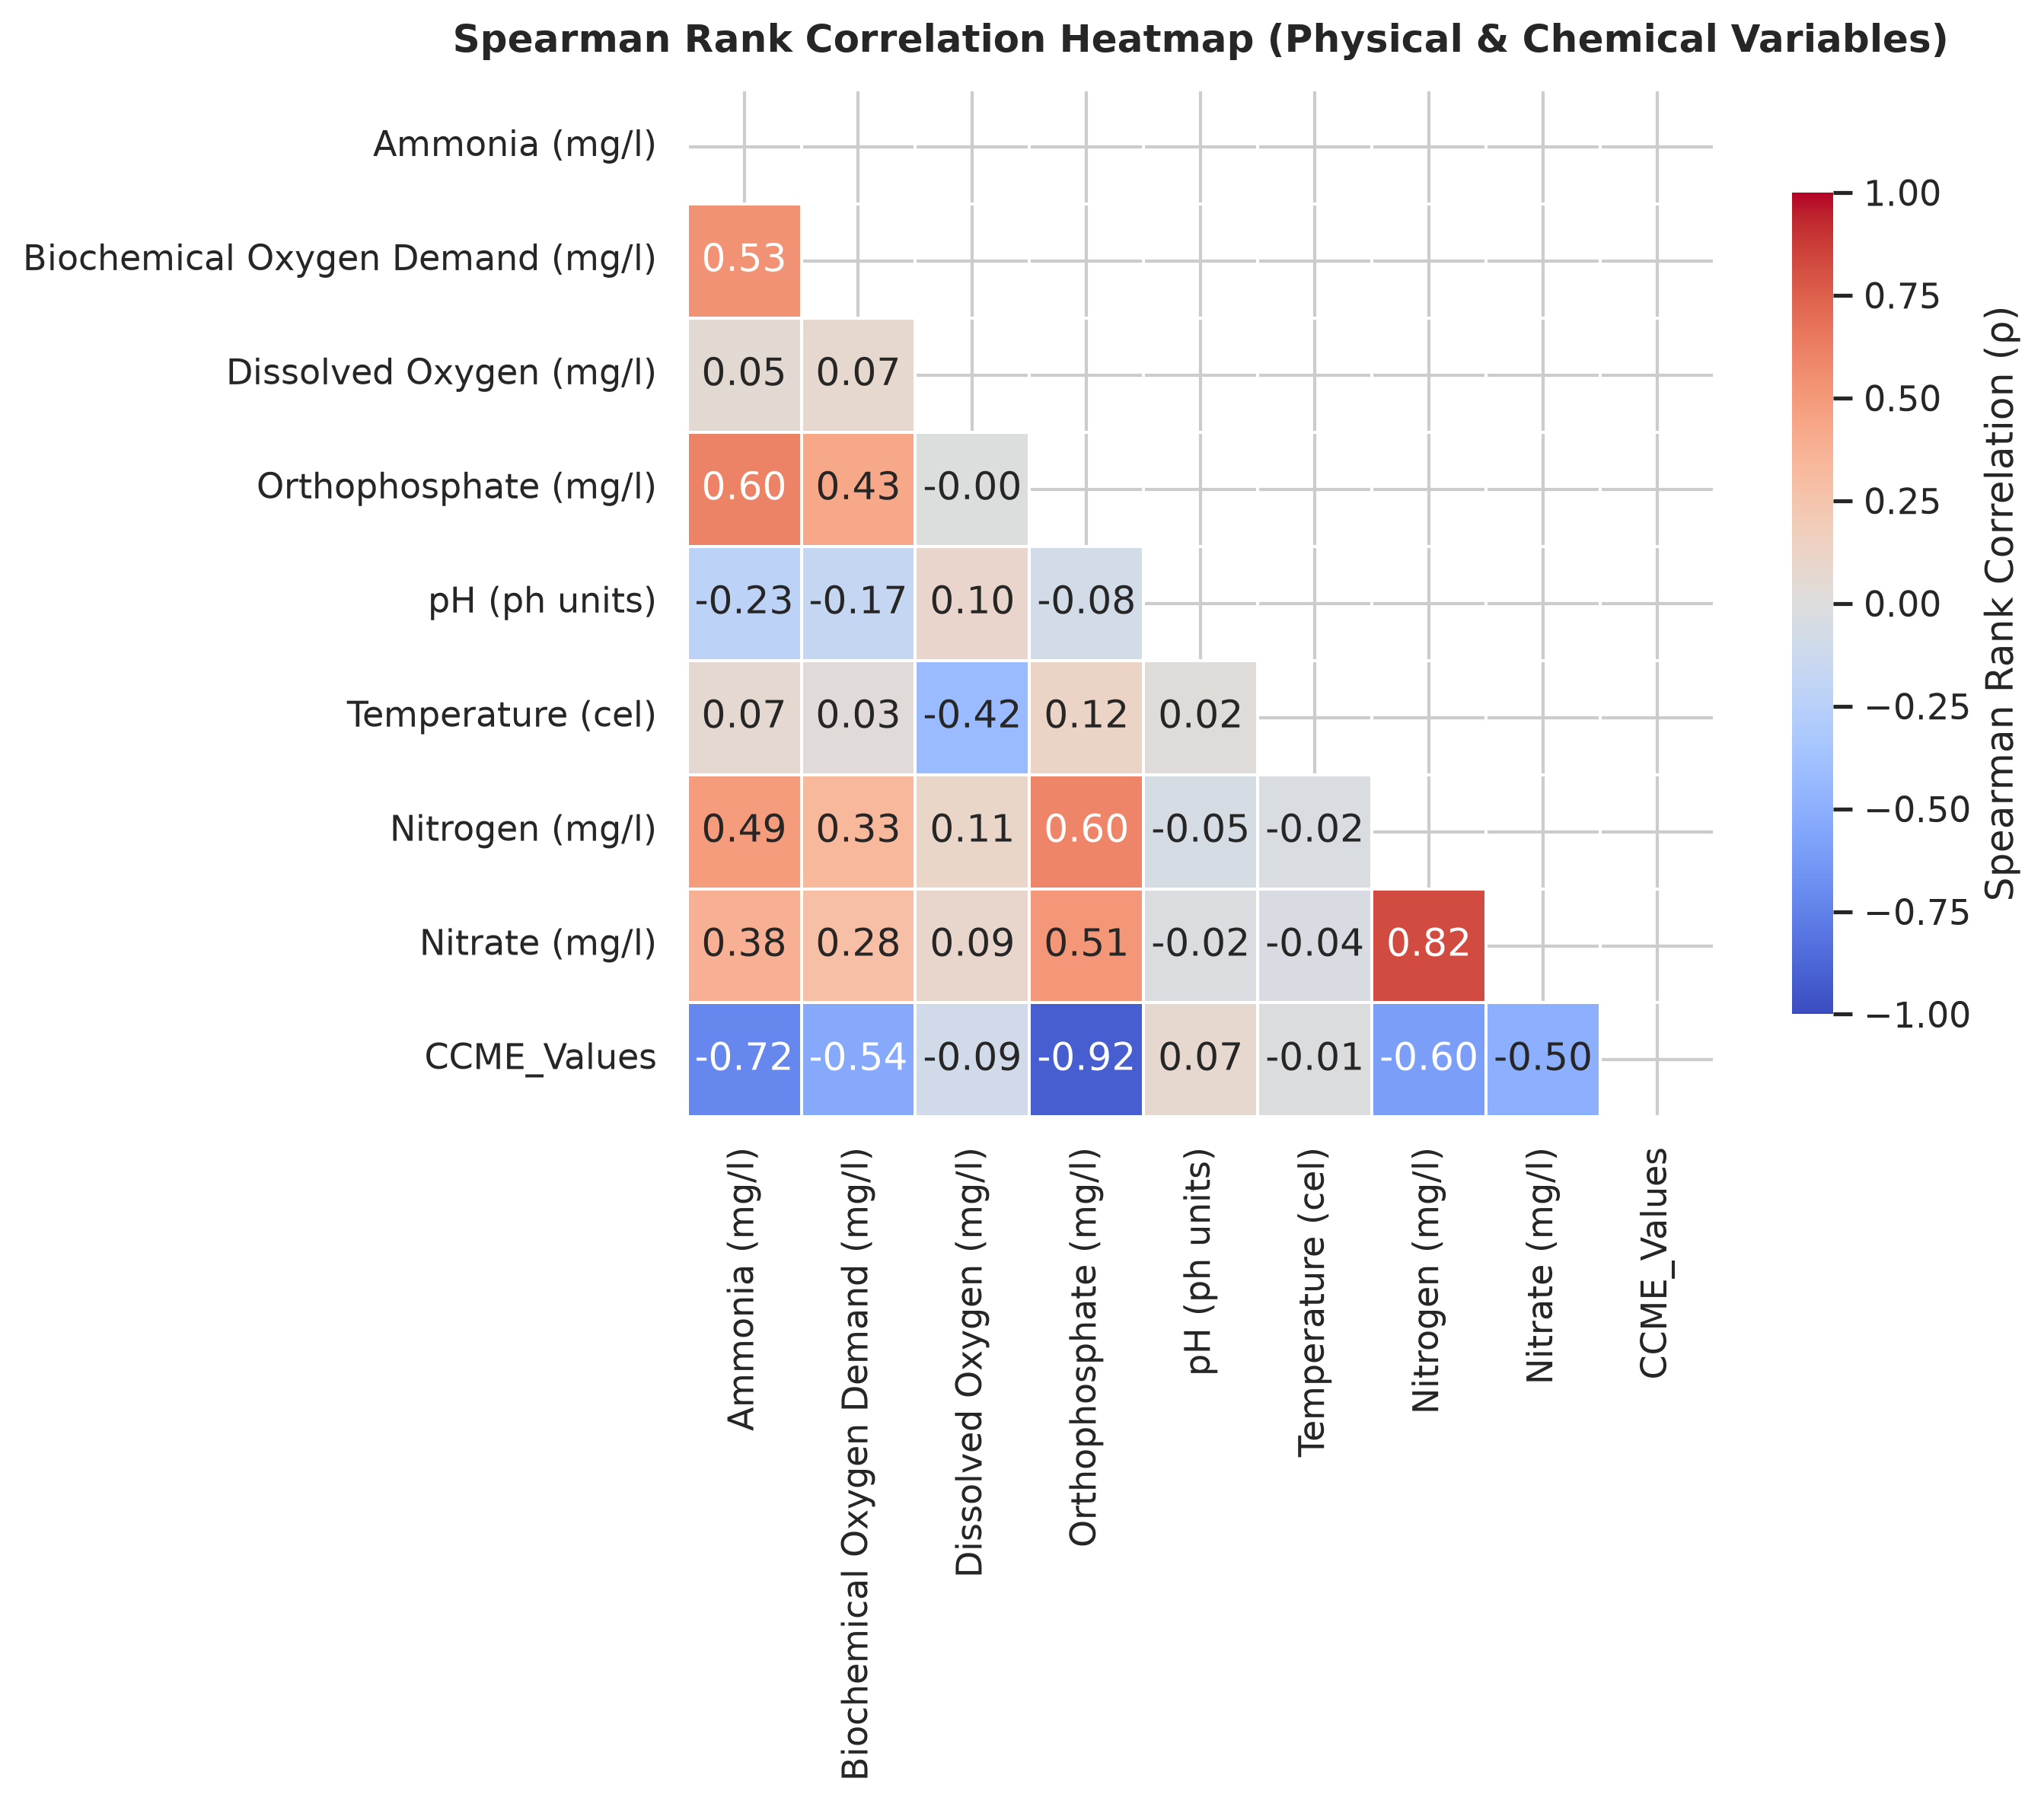

In [11]:
# Display Key Diagnostic Plots Inline

# 1. Missingness Overview
from IPython.display import Image, display
display(Image(filename=saved_figs['missingness_overview']))

# 2. Missingness Synchrony Heatmap
display(Image(filename=saved_figs['missingness_correlation']))

# 3. Feature Distributions
display(Image(filename=saved_figs['numerical_distributions']))

# 4. Outlier Boxplots
display(Image(filename=saved_figs['outlier_boxplots']))

# 5. Target Variable Profiling
display(Image(filename=saved_figs['target_distributions']))

# 6. Correlation Heatmap
display(Image(filename=saved_figs['correlation_matrix']))


## Task 6: Target Variable Identification & Imbalance Analysis

Our dataset defines water quality through two complementary target columns:
1. `CCME_Values` (Continuous / Regression): The exact Canadian Council of Ministers of the Environment Water Quality Index score, ranging from $0.0$ to $100.0$.
2. `CCME_WQI` (Categorical / Classification): Five regulatory grades:
   - **Excellent**: $95 - 100$
   - **Good**: $80 - 94$
   - **Fair**: $65 - 79$
   - **Marginal**: $45 - 64$
   - **Poor**: $0 - 44$

Let us inspect their precise distributions and assess class imbalance risks.


In [12]:
target_audit = audit_target_distribution(df)

for t_name in target_audit.get('identified_targets', []):
    print("=" * 60)
    print(f"TARGET PROFILE: {t_name}")
    print("=" * 60)
    t_info = target_audit[t_name]
    for k, v in t_info.items():
        if k != 'class_breakdown':
            print(f"  {k}: {v}")
        else:
            print("  Class Breakdown:")
            for cls_name, cls_data in v.items():
                print(f"    - {cls_name:10s}: {cls_data['count']:,} ({cls_data['percentage']}%)")
    print()


TARGET PROFILE: CCME_Values
  type: Continuous / Regression
  count: 4297895
  missing: 0
  mean: 89.615
  std: 15.752
  min: 31.304
  q25: 88.269
  median: 100.0
  q75: 100.0
  max: 100.0
  skewness: -1.76

TARGET PROFILE: CCME_WQI
  type: Categorical / Classification
  unique_classes: 5
  Class Breakdown:
    - Excellent : 2,155,328 (50.15%)
    - Good      : 1,368,562 (31.84%)
    - Marginal  : 328,795 (7.65%)
    - Fair      : 318,228 (7.4%)
    - Poor      : 126,982 (2.95%)
  majority_class: Excellent (50.1%)
  minority_class: Poor (3.0%)
  class_imbalance_ratio: 16.97:1



## Task 7: Save Reproducible Audit Report & Figure Artifacts

To maintain rigorous experimental traceability, we compile the entire audit into a self-contained Markdown report (`reports/dataset_audit_report.md`) linking all diagnostic tables, statistics, and figures.


In [13]:
report_path = os.path.join(project_root, 'reports', 'dataset_audit_report.md')
report_text = generate_audit_report(
    df=df,
    dataset_path=selected_file,
    output_path=report_path,
    figures_dir=fig_dir,
)

print(f"Audit report saved successfully: {report_path}")
print(f"Report length: {len(report_text.splitlines())} lines ({len(report_text):,} bytes)")


2026-10-21 14:53:45,780 [INFO] Generating comprehensive audit report at: /Users/chaitanyakumar/Desktop/Semester_5_AML_DL/reports/dataset_audit_report.md


2026-10-21 14:53:51,869 [INFO] Report written successfully to /Users/chaitanyakumar/Desktop/Semester_5_AML_DL/reports/dataset_audit_report.md (199 lines)


Audit report saved successfully: /Users/chaitanyakumar/Desktop/Semester_5_AML_DL/reports/dataset_audit_report.md
Report length: 199 lines (12,384 bytes)


## Task 8: Conclusions & Unresolved Data Quality Issues Handoff

### Summary of Audit Findings

| Data Quality Dimension | Audit Finding | Recommended Preprocessing Action (Role 3) |
|---|---|---|
| **Data Completeness** | 2,827,977 complete rows (65.8%). Overall missing rate 16.1%. | Benchmark baseline tree models on 2.41M complete cases; deploy iterative imputation for continuous telemetry. |
| **Nutrient Missingness** | Ammonia, Orthophosphate, Nitrogen, Nitrate drop together (34.2%). | MAR mechanism confirmed; preserve joint nutrient correlation structure during imputation. |
| **Telemetry Sentinels** | Temperature (80 rows), pH (3 rows), DO (1 row) contain `-999999.0`. | Convert sentinels strictly to `NaN` prior to imputation to avoid neural net gradient explosions. |
| **Sensor Scale Corruptions** | `pH = 67115.0` (uncalibrated multiplier error). | Flag and replace pH values $>14.0$ with `NaN`. |
| **Detection Limit Offsets** | Small negative concentrations (`-0.005 mg/L` to `-2.0 mg/L`). | Clip small negative values in non-negative concentrations to `0.0`. |
| **Duplication** | 10,005 exact duplicate rows (0.233%). | Deduplicate before train/val/test splitting to prevent data leakage. |
| **Target Imbalance** | `CCME_WQI` shows 17:1 imbalance (50.1% Excellent vs 3.0% Poor). | Use stratified splitting (70/15/15 across Country, Waterbody Type, CCME_WQI) and class-weighted loss. |

---
**Audit Pipeline Execution Verified and Ready for Preprocessing.**
